# 02 — Régression linéaire simple : prix ~ surface

**Objectif** : construire un premier modèle, le plus simple possible, et mesurer honnêtement ce qu'il vaut.

1. Découper les données dans le temps (apprendre sur le passé, tester sur le futur)
2. Poser deux baselines, pour savoir ce qu'est un « bon » score
3. Ajuster `prix = a × surface + b` à la main, puis avec scikit-learn et statsmodels
4. Évaluer sur 2025 et analyser les erreurs (résidus)

Les données viennent de `src/prepare_data.py`, qui applique les règles de nettoyage définies dans le notebook 01.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.float_format", "{:,.2f}".format)

BLEU = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e2",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
})

## 1. Chargement des données nettoyées

In [2]:
apparts = pd.read_parquet(Path("..") / "data" / "processed" / "apparts.parquet")
print(f"{len(apparts):,} ventes d'appartements")
apparts.head()

39,817 ventes d'appartements


,id_mutation,date,annee,prix,surface,pieces,a_dependance,code_departement,code_commune,nom_commune,latitude,longitude
0,2021-265064,2021-01-08,2021,"126,188.00",79.00,4,False,18,18033,Bourges,47.08,2.43
1,2021-265077,2021-01-12,2021,"74,500.00",76.00,3,False,18,18033,Bourges,47.08,2.39
2,2021-265079,2021-01-19,2021,"74,000.00",52.00,3,True,18,18033,Bourges,47.08,2.44
3,2021-265092,2021-01-15,2021,"112,000.00",68.00,3,True,18,18033,Bourges,47.08,2.40
4,2021-265110,2021-01-06,2021,"45,000.00",26.00,1,True,18,18033,Bourges,47.09,2.40


## 2. Découpage temporel : apprendre sur 2021-2024, tester sur 2025

Je ne fais **pas** de découpage aléatoire. En pratique, le modèle servira à estimer des ventes **futures** :
il doit donc être évalué sur une période qu'il n'a jamais vue. Un découpage aléatoire mélangerait
des ventes de 2025 dans l'apprentissage et donnerait un score trop optimiste.

In [3]:
train = apparts[apparts["annee"] <= 2024]
test = apparts[apparts["annee"] == 2025]
print(f"Apprentissage (2021-2024) : {len(train):,} ventes")
print(f"Test (2025)               : {len(test):,} ventes ({len(test) / len(apparts):.0%})")

Apprentissage (2021-2024) : 32,235 ventes
Test (2025)               : 7,582 ventes (19%)


In [4]:
def evaluer(nom, y_vrai, y_predit):
    return {
        "modèle": nom,
        "MAE (€)": mean_absolute_error(y_vrai, y_predit),
        "RMSE (€)": mean_squared_error(y_vrai, y_predit) ** 0.5,
        "R²": r2_score(y_vrai, y_predit),
    }

resultats = []

## 3. Les baselines : le score à battre

Un modèle n'a de valeur que comparé à une référence simple.

- **Baseline 1 — prix médian** : on prédit le même prix pour tous les appartements (le prix médian de l'apprentissage).
- **Baseline 2 — prix au m² de la commune** : prix médian au m² de la commune × surface.
  C'est à peu près ce que fait un particulier qui consulte les prix de sa ville.
  Si la commune a moins de 10 ventes dans l'apprentissage, on prend la médiane du département.

Les deux baselines sont calculées **uniquement sur l'apprentissage** : utiliser les prix de 2025 serait de la fuite de données.

In [5]:
# Baseline 1 : prix médian
prix_median = train["prix"].median()
resultats.append(evaluer("Baseline : prix médian", test["prix"], np.full(len(test), prix_median)))

# Baseline 2 : prix médian au m² de la commune × surface
prix_m2_train = train["prix"] / train["surface"]
ventes_par_commune = train.groupby("code_commune").size()
m2_commune = prix_m2_train.groupby(train["code_commune"]).median()[ventes_par_commune >= 10]
m2_departement = prix_m2_train.groupby(train["code_departement"]).median()

m2_test = test["code_commune"].map(m2_commune).fillna(test["code_departement"].map(m2_departement))
pred_baseline_commune = m2_test * test["surface"]
resultats.append(evaluer("Baseline : prix au m² de la commune", test["prix"], pred_baseline_commune))

print(f"Prix médian d'apprentissage : {prix_median:,.0f} €")
print(f"Ventes de test dont la commune a assez d'historique : "
      f"{test['code_commune'].map(m2_commune).notna().mean():.0%}")
pd.DataFrame(resultats).set_index("modèle")

Prix médian d'apprentissage : 110,000 €
Ventes de test dont la commune a assez d'historique : 98%


,MAE (€),RMSE (€),R²
modèle,,,
Baseline : prix médian,"48,203.17","73,161.37",-0.03
Baseline : prix au m² de la commune,"31,335.98","46,522.66",0.58


## 4. La régression linéaire simple

On cherche la droite `prix = a × surface + b` qui minimise la somme des carrés des erreurs (**moindres carrés ordinaires**).
La solution a une formule fermée :

$$a = \frac{\text{cov}(\text{surface}, \text{prix})}{\text{var}(\text{surface})} \qquad b = \overline{\text{prix}} - a \times \overline{\text{surface}}$$

### 4.1 À la main avec NumPy

In [6]:
x = train["surface"].to_numpy()
y = train["prix"].to_numpy()

a = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
b = y.mean() - a * x.mean()
print(f"a = {a:,.1f} €/m²")
print(f"b = {b:,.0f} €")

a = 1,855.0 €/m²
b = 15,114 €


### 4.2 Avec scikit-learn : on doit retrouver les mêmes coefficients

In [7]:
modele = LinearRegression()
modele.fit(train[["surface"]], train["prix"])
print(f"a = {modele.coef_[0]:,.1f} €/m²")
print(f"b = {modele.intercept_:,.0f} €")
assert np.isclose(modele.coef_[0], a) and np.isclose(modele.intercept_, b)

a = 1,855.0 €/m²
b = 15,114 €


### 4.3 Avec statsmodels : la lecture statistique

In [8]:
ols = sm.OLS(train["prix"], sm.add_constant(train["surface"])).fit()
print(f"R² (apprentissage) : {ols.rsquared:.3f}\n")
print(ols.summary().tables[1])

R² (apprentissage) : 0.408

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.511e+04    783.414     19.292      0.000    1.36e+04    1.66e+04
surface     1854.9572     12.433    149.192      0.000    1830.587    1879.327


**Lecture des résultats :**
- **a ≈ 1 855 €/m²** : chaque mètre carré supplémentaire ajoute en moyenne environ 1 855 € au prix.
- **b ≈ 15 000 €** : c'est le prix « prédit » pour 0 m². Il n'a pas de sens physique (aucun appartement ne fait 0 m²) :
  c'est une extrapolation hors des données. On peut le voir comme la part du prix qui ne dépend pas de la surface.
- **p-value < 0,001** pour la surface : l'effet de la surface est statistiquement très significatif.
  L'intervalle de confiance à 95 % est étroit (quelques dizaines d'€/m²) grâce aux 32 000 ventes.
- **R² ≈ 0,4** : la surface explique environ 40 % des variations de prix. Les 60 % restants viennent d'autre chose.

Attention : une p-value très faible veut dire que l'effet existe, **pas** que le modèle prédit bien.

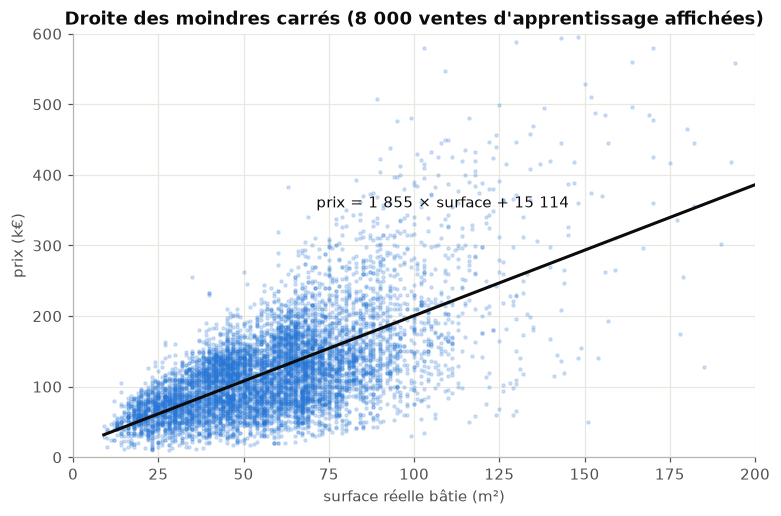

In [9]:
vue = train.sample(8_000, random_state=0)
grille = np.linspace(train["surface"].min(), 200, 100)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(vue["surface"], vue["prix"] / 1000, s=4, alpha=0.2, color=BLEU, rasterized=True)
ax.plot(grille, (a * grille + b) / 1000, color="#0b0b0b", linewidth=2)
ax.annotate(f"prix = {a:,.0f} × surface + {b:,.0f}".replace(",", " "),
            (150, (a * 150 + b) / 1000), xytext=(-10, 28), textcoords="offset points",
            ha="right", color="#0b0b0b")
ax.set(xlim=(0, 200), ylim=(0, 600), xlabel="surface réelle bâtie (m²)", ylabel="prix (k€)",
       title="Droite des moindres carrés (8 000 ventes d'apprentissage affichées)")
plt.show()

## 5. Évaluation sur les ventes de 2025

In [10]:
pred_regression = modele.predict(test[["surface"]])
resultats.append(evaluer("Régression simple : prix ~ surface", test["prix"], pred_regression))

tableau = pd.DataFrame(resultats).set_index("modèle")
tableau.style.format({"MAE (€)": "{:,.0f}", "RMSE (€)": "{:,.0f}", "R²": "{:.3f}"})

,MAE (€),RMSE (€),R²
modèle,,,
Baseline : prix médian,"48,203","73,161",-0.030
Baseline : prix au m² de la commune,"31,336","46,523",0.583
Régression simple : prix ~ surface,"38,985","54,938",0.419


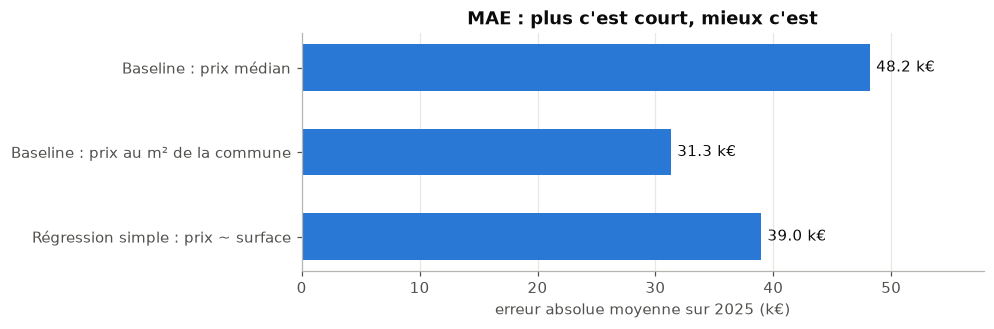

In [11]:
fig, ax = plt.subplots(figsize=(8, 2.8))
mae = tableau["MAE (€)"][::-1]
barres = ax.barh(mae.index, mae.values / 1000, color=BLEU, height=0.55)
ax.bar_label(barres, labels=[f"{v / 1000:.1f} k€" for v in mae.values], padding=4)
ax.set(xlabel="erreur absolue moyenne sur 2025 (k€)", title="MAE : plus c'est court, mieux c'est")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, mae.max() / 1000 * 1.2)
plt.show()

- La régression simple **bat largement** la baseline « prix médian » : la surface apporte de l'information.
- Mais elle fait **moins bien que la baseline « prix au m² de la commune »** : un modèle qui ne connaît que la surface
  ignore où se trouve l'appartement, alors que la localisation pèse énormément sur le prix (notebook 01).

Concrètement : en moyenne, la régression simple se trompe d'environ 39 000 € sur un appartement vendu en 2025.

Note : le R² de la baseline « prix médian » est légèrement **négatif**. Un R² de 0 correspond à prédire la moyenne
des prix de 2025 ; prédire la médiane de 2021-2024 fait un peu moins bien, d'où un R² < 0.

## 6. Analyse des résidus

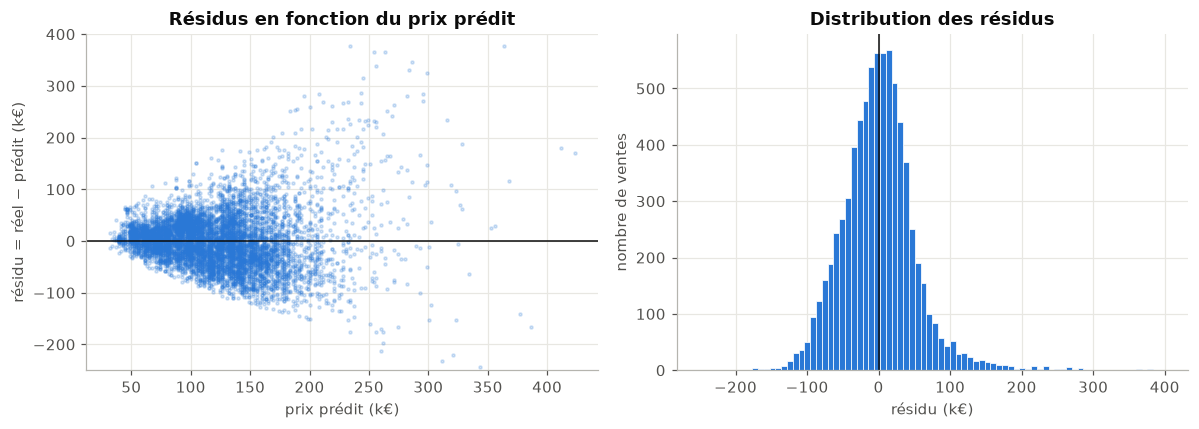

In [12]:
residus = test["prix"] - pred_regression

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(pred_regression / 1000, residus / 1000, s=4, alpha=0.2, color=BLEU, rasterized=True)
ax1.axhline(0, color="#0b0b0b", linewidth=1)
ax1.set(xlabel="prix prédit (k€)", ylabel="résidu = réel − prédit (k€)",
        title="Résidus en fonction du prix prédit", ylim=(-250, 400))

ax2.hist(residus / 1000, bins=80, range=(-250, 400), color=BLEU, edgecolor="white", linewidth=0.5)
ax2.axvline(0, color="#0b0b0b", linewidth=1)
ax2.set(xlabel="résidu (k€)", ylabel="nombre de ventes", title="Distribution des résidus")
fig.tight_layout()
plt.show()

Deux défauts apparaissent :
- **Hétéroscédasticité** : le nuage de résidus s'élargit quand le prix prédit augmente (forme d'entonnoir).
  L'erreur est proportionnelle à la taille du bien : se tromper de 30 000 € sur un T1 est grave, sur un T5 beaucoup moins.
  Une piste classique : modéliser le **logarithme du prix**.
- **Asymétrie** : la distribution des résidus a une longue queue à droite (quelques appartements bien plus chers que prévu).

In [13]:
noms_dep = {"18": "Cher", "28": "Eure-et-Loir", "36": "Indre",
            "37": "Indre-et-Loire", "41": "Loir-et-Cher", "45": "Loiret"}
biais = (
    pd.DataFrame({"departement": test["code_departement"].map(noms_dep),
                  "residu": residus, "residu_relatif": residus / pred_regression})
    .groupby("departement")
    .agg(ventes=("residu", "size"), residu_median=("residu", "median"),
         ecart_median=("residu_relatif", "median"))
    .sort_values("residu_median")
)
biais.style.format({"residu_median": "{:+,.0f} €", "ecart_median": "{:+.0%}"})

,ventes,residu_median,ecart_median
departement,,,
Indre,234,"-53,095 €",-44%
Cher,591,"-36,022 €",-32%
Loir-et-Cher,579,"-18,877 €",-19%
Eure-et-Loir,1074,"-2,911 €",-3%
Loiret,2403,+848 €,+1%
Indre-et-Loire,2701,"+19,947 €",+20%


Les résidus révèlent un **biais géographique systématique** :
- dans l'**Indre** et le **Cher**, le modèle **surestime** les prix (résidu négatif : réel < prédit) ;
- en **Indre-et-Loire**, il les **sous-estime**.

Le modèle applique le même prix au m² partout, alors qu'un m² vaut deux fois plus cher à Tours qu'à Châteauroux.
C'est exactement l'information qui manque.

## 7. Conclusions

| Ce qu'on a appris | Conséquence pour la suite |
|---|---|
| La surface explique environ 40 % des variations de prix (R²) | il faut d'autres variables |
| La régression simple bat la baseline naïve mais pas la baseline « prix au m² de la commune » | la **localisation** est la variable manquante la plus importante |
| Les résidus sont biaisés par département | ajouter le département, la commune ou les coordonnées GPS |
| Les erreurs grandissent avec le prix (hétéroscédasticité) | tester une régression sur le **log du prix** |

**Prochaine étape (notebook 03)** : régression linéaire multiple avec surface, nombre de pièces, localisation,
année de vente et présence d'une dépendance, puis diagnostic (VIF, résidus) et régularisation Ridge / Lasso.